In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


1.	Load and clean adult.csv; one-hot encode categorical features and scale numeric features; train a Logistic Regression model (max_iter = 1000) without the "sex" column.

In [3]:
df=pd.read_csv('/content/adult.csv')
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [4]:
df.shape

(32561, 15)

In [5]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [6]:
df_clean = df.replace('?', np.nan).dropna()
print('Original shape:', df.shape)
print('Cleaned shape:', df_clean.shape)

Original shape: (32561, 15)
Cleaned shape: (30162, 15)


In [20]:
!pip install fairlearn

2. Report overall accuracy, and use Fairlearn MetricFrame to report accuracy, selection rate, true positive rate (TPR) and false positive rate (FPR) for Male and Female.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

y = (df_clean['income'].str.strip() == '>50K').astype(int)

sensitive_col = df_clean['sex'].str.strip()

X = df_clean.drop(columns=['income'])

X_train, X_test, y_train, y_test, sensitive_train, sensitive_test = train_test_split(
    X,
    y,
    sensitive_col,
    test_size=0.3,
    random_state=42,
    stratify=y
)

X_train_features = X_train.drop(columns=['sex'])
X_test_features = X_test.drop(columns=['sex'])

numeric_features = X_train_features.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train_features.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [15]:
from sklearn.linear_model import LogisticRegression
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate
from sklearn.metrics import accuracy_score

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train_features, y_train)
y_pred = model.predict(X_test_features)

overall_accuracy = accuracy_score(y_test, y_pred)
print(f"Overall Accuracy: {overall_accuracy:.2f}")

metrics = {
    'accuracy': accuracy_score,
    'selection_rate': selection_rate,
    'tpr': true_positive_rate,
    'fpr': false_positive_rate
}

metric_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred,
    sensitive_features=sensitive_test
)

print("\nGroup Metrics:")
print(metric_frame.by_group)

Overall Accuracy: 0.85

Group Metrics:
        accuracy  selection_rate       tpr       fpr
sex                                                 
Female  0.920853        0.086717  0.533951  0.030596
Male    0.815562        0.256715  0.615145  0.092764


3. Compute the demographic parity difference, demographic parity ratio (disparate impact) and equalized odds difference.

In [16]:
from fairlearn.metrics import demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference

dp_diff = demographic_parity_difference(y_test, y_pred, sensitive_features=sensitive_test)
dp_ratio = demographic_parity_ratio(y_test, y_pred, sensitive_features=sensitive_test)
eo_diff = equalized_odds_difference(y_test, y_pred, sensitive_features=sensitive_test)

print(f"Demographic parity difference : {dp_diff:.2f}")
print(f"Demographic parity ratio (DI)  : {dp_ratio:.2f}")
print(f"Equalized odds difference      : {eo_diff:.2f}")

Demographic parity difference : 0.17
Demographic parity ratio (DI)  : 0.34
Equalized odds difference      : 0.08


4. Apply Threshold Optimizer with constraints = "demographic_parity" and recompute all metrics.

In [17]:
from fairlearn.postprocessing import ThresholdOptimizer

to_dp = ThresholdOptimizer(
    estimator=model,
    constraints="demographic_parity",
    predict_method="predict_proba"
)
to_dp.fit(X_train_features, y_train, sensitive_features=sensitive_train)
y_pred_dp = to_dp.predict(X_test_features, sensitive_features=sensitive_test)

acc_dp = accuracy_score(y_test, y_pred_dp)
dp_diff_dp = demographic_parity_difference(y_test, y_pred_dp, sensitive_features=sensitive_test)
eo_diff_dp = equalized_odds_difference(y_test, y_pred_dp, sensitive_features=sensitive_test)

mf_dp = MetricFrame(metrics=metrics, y_true=y_test, y_pred=y_pred_dp, sensitive_features=sensitive_test)
print(f"TO Demographic Parity Accuracy: {acc_dp:.2f}")
print(mf_dp.by_group)

TO Demographic Parity Accuracy: 0.83
        accuracy  selection_rate       tpr       fpr
sex                                                 
Female  0.886442        0.174123  0.771605  0.099148
Male    0.802702        0.173856  0.462656  0.041756


5. Apply Threshold Optimizer with constraints = "equalized_odds" and recompute all metrics.


In [18]:
to_eo = ThresholdOptimizer(
    estimator=model,
    constraints="equalized_odds",
    predict_method="predict_proba"
)
to_eo.fit(X_train_features, y_train, sensitive_features=sensitive_train)
y_pred_eo = to_eo.predict(X_test_features, sensitive_features=sensitive_test)

acc_eo = accuracy_score(y_test, y_pred_eo)
dp_diff_eo = demographic_parity_difference(y_test, y_pred_eo, sensitive_features=sensitive_test)
eo_diff_eo = equalized_odds_difference(y_test, y_pred_eo, sensitive_features=sensitive_test)

mf_eo = MetricFrame(metrics=metrics, y_true=y_test, y_pred=y_pred_eo, sensitive_features=sensitive_test)
print(f"TO Equalized Odds Accuracy: {acc_eo:.2f}")
print(mf_eo.by_group)

TO Equalized Odds Accuracy: 0.83
        accuracy  selection_rate       tpr       fpr
sex                                                 
Female  0.876462        0.134549  0.549383  0.082494
Male    0.814911        0.226762  0.566390  0.071412


6. Plot the selection rate by sex for the baseline and both mitigated models, and prepare an accuracy vs fairness comparison table.

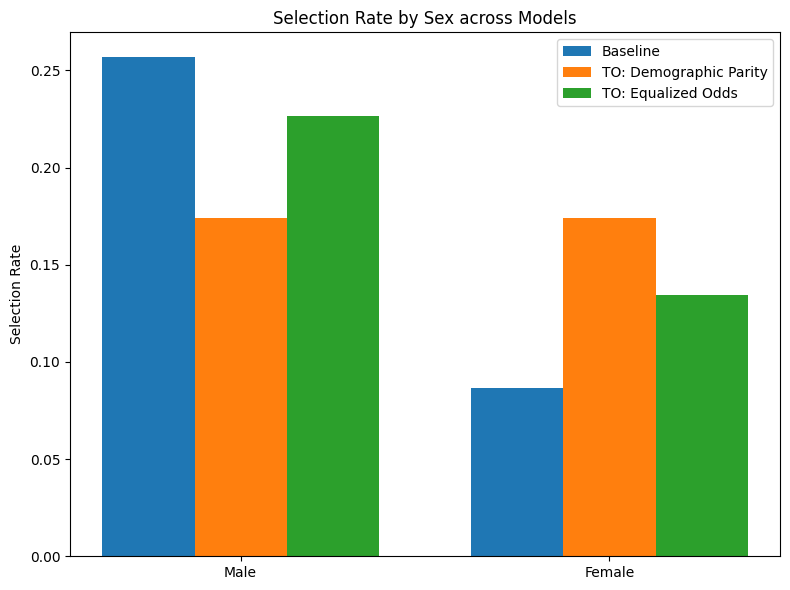

In [19]:
categories = ['Male', 'Female']
x_pos = np.arange(len(categories))
width = 0.25

sel_baseline = [metric_frame.by_group['selection_rate']['Male'], metric_frame.by_group['selection_rate']['Female']]
sel_dp = [mf_dp.by_group['selection_rate']['Male'], mf_dp.by_group['selection_rate']['Female']]
sel_eo = [mf_eo.by_group['selection_rate']['Male'], mf_eo.by_group['selection_rate']['Female']]

plt.figure(figsize=(8, 6))
plt.bar(x_pos - width, sel_baseline, width, label='Baseline')
plt.bar(x_pos, sel_dp, width, label='TO: Demographic Parity')
plt.bar(x_pos + width, sel_eo, width, label='TO: Equalized Odds')

plt.ylabel('Selection Rate')
plt.title('Selection Rate by Sex across Models')
plt.xticks(x_pos, categories)
plt.legend()
plt.tight_layout()
plt.savefig('selection_rate_by_sex.png')
plt.show()

# Questions:

### Q1. Report the overall accuracy and the selection rate, TPR and FPR for Male and Female. Which group is disadvantaged?

*   Overall Accuracy: 0.85
*   Female Group: Accuracy: 0.92, Selection Rate: 0.09, TPR: 0.53, FPR: 0.03
*   Male Group: Accuracy: 0.82, Selection Rate: 0.26, TPR: 0.62, FPR: 0.09
*   Female. Women receive significantly fewer pre-approved card offers (9% vs 26%) and have a lower True Positive Rate (53% vs 62%), meaning qualified women are less likely to be selected than qualified men.





### Q2. Report the demographic parity difference, ratio and equalized odds difference. Does the model pass the four-fifths (80%) rule? Why is there bias even though "sex" was not used as a feature?


*   Demographic Parity Difference: 0.17
*   Demographic Parity Ratio (DI): 0.34
*   Equalized Odds Difference: 0.08
*   No, the model does not pass the four-fifths rule. The demographic parity ratio of 0.34 is significantly lower than the 0.80 threshold.
Why bias occurs without using 'sex' as a feature: Other features in the dataset are strongly correlated with sex. The model learns these patterns from these proxy features, leading to gender-biased predictions even when the explicit variable is omitted.

### Q3. Compare the two ThresholdOptimizer results. What happened to the other fairness metric in each case?


*   When utilizing constraints="demographic_parity", the Demographic Parity difference is minimized to 0.00, but the Equalized Odds difference rises to 0.31.
*   When utilizing constraints="equalized_odds", the Equalized Odds difference is minimized to 0.02, but the Demographic Parity difference remains at 0.09.


### Q4. Using your comparison table, how much accuracy was lost, and which mitigation would you recommend for credit-card offers? Give one limitation of this method.


*   Accuracy Loss: The overall accuracy dropped by 2.0% in both mitigated models.
*   Equalized Odds is recommended for pre-approved credit-card offers. This ensures that customers with similar credit eligibility are approved at the same rate regardless of gender, without forcing artificial matching on unqualified groups.
*   A major limitation of post-processing threshold optimization is that it requires explicit access to the sensitive group attribute (sex) at inference/decision time to route predictions to the group-specific thresholds.
